# Coursework 1

This notebook contains the PyTorch code for the baseline experiments in coursework 1. You may modify your solutions from here.


## Imports and data/model helpers

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# Change only this line to switch between 'mps', 'cpu', or 'cuda'.
device = torch.device('mps')
print(f'Running on: {device}')

plt.style.use('ggplot')

Running on: mps


In [2]:
%matplotlib inline
plt.style.use('ggplot')

DATA_DIR = Path('../data').resolve()

def load_emnist(which_set):
    loaded = np.load(DATA_DIR / f'emnist-{which_set}.npz')
    inputs = torch.from_numpy(loaded['inputs']).to(torch.float32)
    inputs = inputs.reshape(-1, 28 * 28) / 255.0
    targets = torch.from_numpy(loaded['targets']).to(torch.long)
    return TensorDataset(inputs, targets)

def make_data_loaders(batch_size=100, seed=111020):
    train_generator = torch.Generator().manual_seed(seed)
    train_data = DataLoader(
        load_emnist('train'), batch_size=batch_size, shuffle=True,
        drop_last=True, generator=train_generator)
    valid_data = DataLoader(
        load_emnist('valid'), batch_size=batch_size, shuffle=False,
        drop_last=True)
    return train_data, valid_data

# 784 → 128 → 128 → 128 → 47
def make_mlp(num_hidden_layers=2, hidden_dim=128, activation=nn.ReLU,
             dropout_keep=None):
    layers = []
    input_dim = 784
    for _ in range(num_hidden_layers):
        layers.append(nn.Linear(input_dim, hidden_dim))
        if dropout_keep is not None:
            # The coursework parameter is an inclusion/keep probability.
            layers.append(nn.Dropout(p=1.0 - dropout_keep))
        layers.append(activation())
        input_dim = hidden_dim
    layers.append(nn.Linear(input_dim, 47))
    model = nn.Sequential(*layers)
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    return model

## Training 

The function below shows how we define the training functions in the experiment.

In [3]:
def evaluate(model, data_loader, criterion):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    with torch.no_grad():
        for inputs, targets in data_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)
            logits = model(inputs)
            total_loss += criterion(logits, targets).item() * targets.size(0)
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            total_examples += targets.size(0)
    return total_loss / total_examples, total_correct / total_examples

def train_model(model, train_data, valid_data, num_epochs,
                               stats_interval=1, learning_rate=1e-3,
                               criterion=None, eval_criterion=None,
                               regularizer=None):
    # regularizer(model), when supplied, is added only before backward().
    if criterion is None:
        criterion = nn.CrossEntropyLoss()
    if eval_criterion is None:
        eval_criterion = nn.CrossEntropyLoss()
    criterion = criterion.to(device)
    eval_criterion = eval_criterion.to(device)
    optimiser = torch.optim.Adam(model.parameters(), lr=learning_rate)
    stats = []
    gradient_history = []

    train_loss, train_acc = evaluate(model, train_data, eval_criterion)
    valid_loss, valid_acc = evaluate(model, valid_data, eval_criterion)
    stats.append([train_loss, valid_loss, train_acc, valid_acc])

    for epoch in range(1, num_epochs + 1):
        model.train()
        first_batch_gradients = None
        for inputs, targets in train_data:
            inputs = inputs.to(device)
            targets = targets.to(device)
            optimiser.zero_grad()
            logits = model(inputs)
            loss = criterion(logits, targets)
            if regularizer is not None:
                loss = loss + regularizer(model)
            loss.backward()
            if first_batch_gradients is None:
                first_batch_gradients = [
                    parameter.grad.detach().abs().mean().item()
                    if parameter.grad is not None else 0.0
                    for parameter in model.parameters() if parameter.requires_grad
                ]
            optimiser.step()
        gradient_history.append(first_batch_gradients)

        if epoch % stats_interval == 0:
            train_loss, train_acc = evaluate(model, train_data, eval_criterion)
            valid_loss, valid_acc = evaluate(model, valid_data, eval_criterion)
            stats.append([train_loss, valid_loss, train_acc, valid_acc])

    stats = np.asarray(stats)
    keys = {'error(train)': 0, 'error(valid)': 1,
            'acc(train)': 2, 'acc(valid)': 3}
    return stats, keys, np.asarray(gradient_history)

## Plotting 

These functions shows how results from training can be plotted.

In [4]:
def plot_learning_curves(results, save_prefix=None):
    """Plot stored metrics only; results maps model labels to experiment records."""
    loss_fig, loss_ax = plt.subplots(figsize=(6, 3.8))
    acc_fig, acc_ax = plt.subplots(figsize=(6, 3.8))
    colours = plt.rcParams['axes.prop_cycle'].by_key()['color']
    for index, (label, result) in enumerate(results.items()):
        values = result['stats']
        epochs = np.arange(1, len(values))  # Row zero is the untrained model.
        colour = colours[index % len(colours)]
        for ax, train_column, valid_column in ((loss_ax, 0, 1), (acc_ax, 2, 3)):
            ax.plot(epochs, values[1:, train_column], color=colour, label=f'{label} (train)')
            ax.plot(epochs, values[1:, valid_column], color=colour,
                    linestyle='--', label=f'{label} (valid)')
    for ax in (loss_ax, acc_ax):
        ax.set_xlabel('Epoch number')
        ax.legend(fontsize=9, ncol=2)
    loss_ax.set_ylabel('Cross-entropy loss')
    acc_ax.set_ylabel('Accuracy')
    loss_fig.tight_layout()
    acc_fig.tight_layout()
    if save_prefix is not None:
        save_prefix = Path(save_prefix)
        save_prefix.parent.mkdir(parents=True, exist_ok=True)
        loss_fig.savefig(f'{save_prefix}_loss.png', dpi=300, bbox_inches='tight')
        acc_fig.savefig(f'{save_prefix}_accuracy.png', dpi=300, bbox_inches='tight')
    return loss_fig, loss_ax, acc_fig, acc_ax

def plot_gradient_flow(result):
    figure, axis = plt.subplots(figsize=(8, 4))
    for gradients in result['gradients']:
        axis.plot(gradients, alpha=0.3, color='b')
    names = result['parameter_names']
    axis.set_xticks(range(len(names)))
    axis.set_xticklabels(names, rotation=90)
    axis.set_ylabel('Mean absolute gradient (first batch)')
    axis.set_title('Gradient flow')
    axis.grid(True)
    figure.tight_layout()
    return figure, axis

## Experiments

All experiments use seed **111020**, Adam learning rate **0.001**, batch size **100**,
and **100 epochs**. The below code shows how the baseline overfitting experiment, as well as the varying network width and depth exepriments, are constructed.


In [5]:
import csv
import json
import random

SEED = 111020
BATCH_SIZE = 100
LEARNING_RATE = 0.001
NUM_EPOCHS = 100

ROOT = DATA_DIR.parent
RESULTS_DIR = ROOT / 'notebooks' / 'task1_results'
TEMPLATE_DIR = ROOT.parent / 'MLP2026-27-CW1-Template'
FIGURES_DIR = TEMPLATE_DIR / 'figures'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

COMMON_SETTINGS = {
    'seed': SEED, 'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE, 'num_epochs': NUM_EPOCHS,
}

def reset_seeds():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

def run_experiment(num_hidden_layers, hidden_dim):
    """Load completed metrics or train a fresh seeded model."""
    config = dict(COMMON_SETTINGS, num_hidden_layers=num_hidden_layers,
                  hidden_dim=hidden_dim, device=str(device))
    name = f'depth{num_hidden_layers}_width{hidden_dim}'
    result_path = RESULTS_DIR / f'{name}.npz'

    reset_seeds()
    train_loader, valid_loader = make_data_loaders(batch_size=BATCH_SIZE, seed=SEED)
    model = make_mlp(num_hidden_layers=num_hidden_layers, hidden_dim=hidden_dim).to(device)
    print(f'Training {name}: seed={SEED}, epochs={NUM_EPOCHS}, device={device}', flush=True)
    stats, _, gradients = train_model(
        model, train_loader, valid_loader, num_epochs=NUM_EPOCHS,
        stats_interval=1, learning_rate=LEARNING_RATE)
    assert stats.shape == (NUM_EPOCHS + 1, 4) and np.isfinite(stats).all()
    parameter_names = [name for name, parameter in model.named_parameters()
                       if parameter.requires_grad]
    torch.save(model.state_dict(), RESULTS_DIR / f'{name}_weights.pt')
    np.savez(result_path, stats=stats, gradients=gradients,
             parameter_names=np.asarray(parameter_names), config=json.dumps(config, sort_keys=True))
    print(f'Finished {name}: validation accuracy={stats[-1, 3]:.2%}', flush=True)
    return {'stats': stats, 'gradients': gradients,
            'parameter_names': parameter_names, 'config': config}

def export_table(results, csv_name, parameter_label):
    """Report epoch-100 metrics, with validation accuracy in percent."""
    rows = []
    print(f'{parameter_label:>13} | Val. accuracy (%) | Train CE | Valid CE')
    for parameter, result in results.items():
        final = result['stats'][-1]
        row = [parameter, 100 * final[3], final[0], final[1]]
        rows.append(row)
        print(f'{parameter:>13} | {row[1]:17.2f} | {row[2]:8.4f} | {row[3]:8.4f}')
    with (RESULTS_DIR / csv_name).open('w', newline='', encoding='utf-8') as handle:
        writer = csv.writer(handle)
        writer.writerow([parameter_label, 'validation_accuracy_percent',
                         'train_cross_entropy', 'validation_cross_entropy'])
        writer.writerows(rows)
    return rows

## Figure 1 baseline

In [6]:
baseline_result = run_experiment(num_hidden_layers=2, hidden_dim=128)
stats = baseline_result['stats']
keys = {'error(train)': 0, 'error(valid)': 1, 'acc(train)': 2, 'acc(valid)': 3}

Training depth2_width128: seed=111020, epochs=100, device=mps
Finished depth2_width128: validation accuracy=81.22%


## Width variation experiments

In [8]:
widths = (32, 64, 128)
width_results = {}
for hidden_units in widths:
    width_results[hidden_units] = run_experiment(num_hidden_layers=1, hidden_dim=hidden_units)

Training depth1_width32: seed=111020, epochs=100, device=mps
Finished depth1_width32: validation accuracy=78.58%
Training depth1_width64: seed=111020, epochs=100, device=mps
Finished depth1_width64: validation accuracy=81.25%
Training depth1_width128: seed=111020, epochs=100, device=mps
Finished depth1_width128: validation accuracy=81.27%


## Depth variation experiments


In [9]:
depths = (1, 2, 3)
depth_results = {}
for hidden_layers in depths:
    depth_results[hidden_layers] = run_experiment(num_hidden_layers=hidden_layers, hidden_dim=128)

Training depth1_width128: seed=111020, epochs=100, device=mps
Finished depth1_width128: validation accuracy=81.27%
Training depth2_width128: seed=111020, epochs=100, device=mps
Finished depth2_width128: validation accuracy=81.22%
Training depth3_width128: seed=111020, epochs=100, device=mps
Finished depth3_width128: validation accuracy=82.13%


## Experiment results plotting

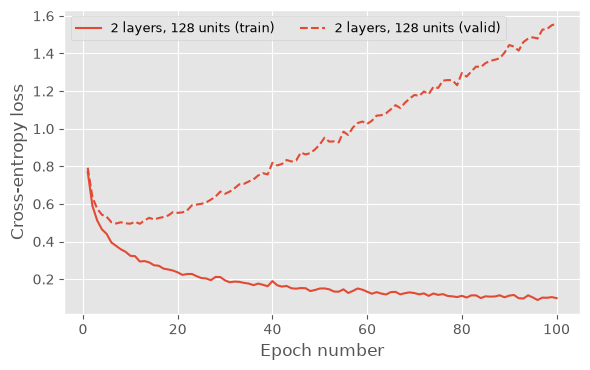

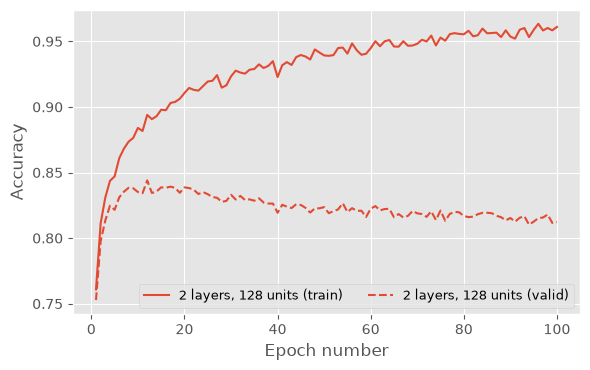

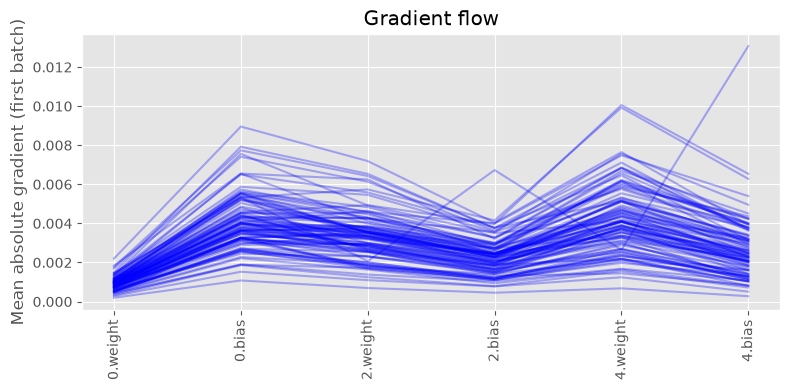

In [10]:
fig_1, ax_1, fig_2, ax_2 = plot_learning_curves({'2 layers, 128 units': baseline_result})
grad_plot, grad_ax = plot_gradient_flow(baseline_result)